# NE 630 — Lesson 24: from depletion to the linear reactivity model

**LAST TIME:** depletion at prescribed flux, burnup, and reactivity.

**TODAY:** compare fixed flux with fixed power, fit the fixed-power fuel-reactivity curve, and use that fit to estimate equilibrium batch cycle lengths and discharge burnups.

## 1. Review: reactivity at fixed flux

Use `ne630_depletion` with the same Table-3.2 data, U-238 shielding correction, expanded actinide chain, and explicit I/Xe and Pm/Sm chains as Lesson 23. The spectrum and microscopic cross sections remain fixed in both calculations below. Initially there is no B-10 or Gd-157 loading.

We evaluate $\rho_\infty=1-1/k_\infty$ using the prescribed-spectrum production/absorption balance. Set nonleakage to one here; the LRM will introduce a separate leakage penalty later.

In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from ne630_depletion import (
    DAY, YEAR, BARN, KAPPA_J, UO2Shielding, Cell,
    three_group_xs, condense, uo2_initial, solve_depletion,
)

ENRICHMENT = 0.04
FUEL_DENSITY = 10.4                    # g UO2/cm^3
FUEL_DIAMETER = 0.82                   # cm
SPECTRUM = (0.35, 0.55, 0.10)          # FAST, INTERMEDIATE, THERMAL
POWER_DENSITY = 300.0                  # W/cm^3 fuel
DURATION_YEARS = 3.5                   # full-power years for the power case
CLOSURE = "rate_ratio"

fresh = uo2_initial(ENRICHMENT, FUEL_DENSITY)
xs3 = three_group_xs(shielding=UO2Shielding(FUEL_DENSITY, FUEL_DIAMETER))
xs1 = condense(xs3, SPECTRUM)
cell = Cell(nonleakage=1.0)
times = np.unique(np.r_[0., np.geomspace(60., 30*DAY, 80),
                        np.linspace(30*DAY, DURATION_YEARS*YEAR, 601)])
common = dict(time_s=times, initial=fresh, model=3,
              spectrum=SPECTRUM, xs3=xs3, cell=cell)

# Match the initial power of the two histories.
sigma_f_initial = BARN * sum(n * xs1[name].fission_b for name, n in fresh.items())
INITIAL_FLUX = POWER_DENSITY / (KAPPA_J * sigma_f_initial)
fixed_flux = solve_depletion(**common, total_flux=INITIAL_FLUX)
print(f"Initial flux: {INITIAL_FLUX:.4e} n/cm^2/s")
print(f"Initial power: {fixed_flux.power_density_w_cm3[0]:.2f} W/cm^3 fuel")

Initial flux: 1.4996e+14 n/cm^2/s
Initial power: 300.00 W/cm^3 fuel


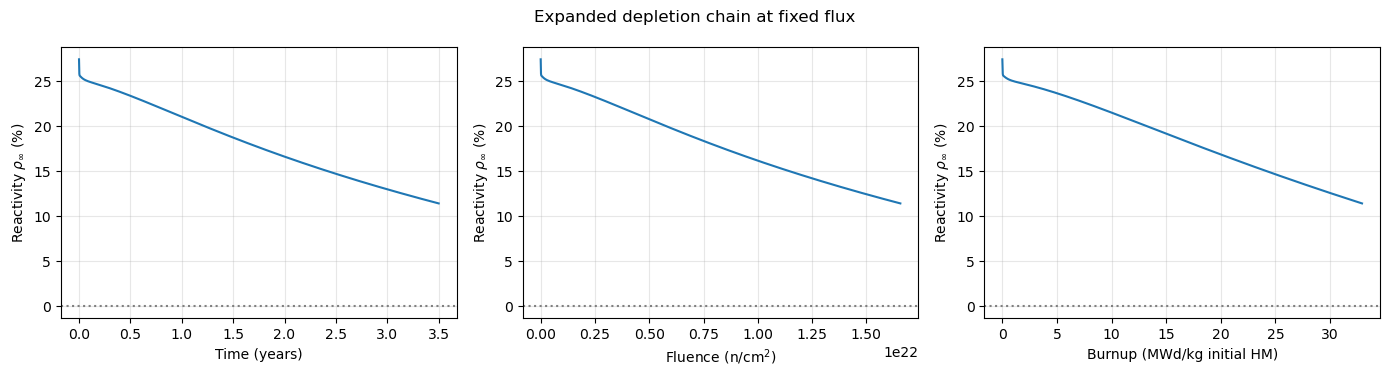

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, axis in zip(axes, ("time", "fluence", "burnup")):
    x, label = fixed_flux.axis(axis, time_unit="years")
    ax.plot(x, 100*fixed_flux.neutronics(CLOSURE)["rho"])
    ax.axhline(0, color="gray", linestyle=":")
    ax.set(xlabel=label, ylabel=r"Reactivity $\rho_\infty$ (%)")
    ax.grid(alpha=0.3)
fig.suptitle("Expanded depletion chain at fixed flux")
fig.tight_layout()
plt.show()

Time and fluence are proportional at fixed flux, but burnup is not proportional to either: the fission rate changes as fuel depletes. The imposed flux can continue after the fuel becomes subcritical; this history alone does not establish sustained reactor operation.

## 2. Hold power fixed instead

For a specified fuel power density $P^{\prime\prime\prime}$,

$$P^{\prime\prime\prime}=\kappa\phi(t)\sum_i\bar\sigma_{fi}N_i(t),\qquad
\phi(t)=\frac{P^{\prime\prime\prime}}{\kappa\sum_i\bar\sigma_{fi}N_i(t)}.$$

The module recomputes this flux during integration. Neutron reaction rates scale with this flux; radioactive decay rates retain their physical time dependence. Simply relabeling a fixed-flux trajectory with a constant-power time axis would miss that distinction.

With $\kappa=200$ MeV/fission, constant power gives

$$B(t)=\frac{P^{\prime\prime\prime}t}{8.64\times10^{10}\rho_{\rm HM,0}},$$

where $\rho_{\rm HM,0}$ is the initial heavy-metal density in kg/cm³ and $B$ is in MWd/kg initial HM. Numerically, MWd/kg and GWd/t are equal.

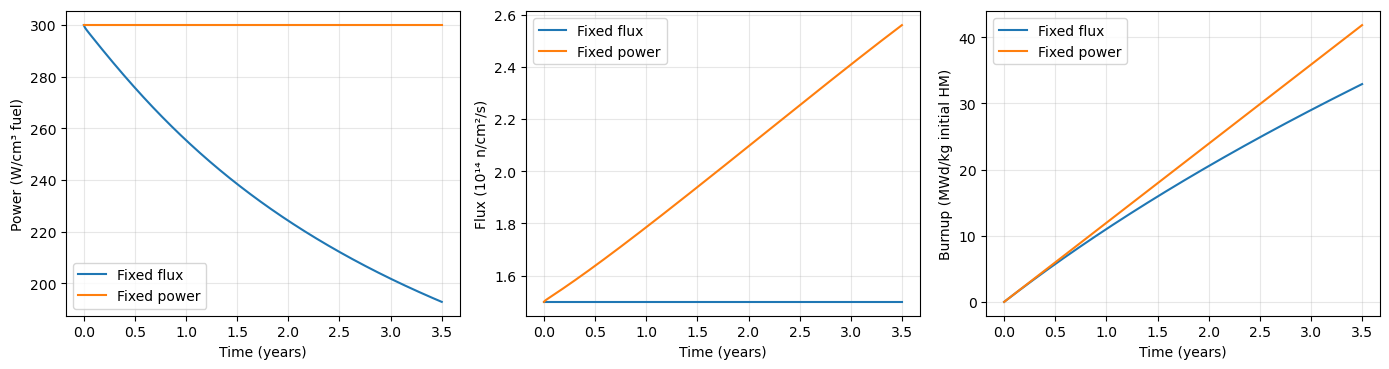

In [3]:
fixed_power = solve_depletion(**common, power_density_w_cm3=POWER_DENSITY)
expected_burnup = POWER_DENSITY * times / (8.64e10 * fixed_power.initial_hm_kg_cm3)
np.testing.assert_allclose(fixed_power.power_density_w_cm3, POWER_DENSITY, rtol=1e-10)
np.testing.assert_allclose(fixed_power.burnup_mwd_kg, expected_burnup, rtol=1e-7, atol=1e-10)

histories = {"Fixed flux": fixed_flux, "Fixed power": fixed_power}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for label, r in histories.items():
    flux = np.broadcast_to(r.total_flux, r.time_s.shape)
    axes[0].plot(r.time_s/YEAR, r.power_density_w_cm3, label=label)
    axes[1].plot(r.time_s/YEAR, flux/1e14, label=label)
    axes[2].plot(r.time_s/YEAR, r.burnup_mwd_kg, label=label)
for ax, ylabel in zip(axes, ("Power (W/cm³ fuel)", "Flux (10¹⁴ n/cm²/s)", "Burnup (MWd/kg initial HM)")):
    ax.set(xlabel="Time (years)", ylabel=ylabel)
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
plt.show()

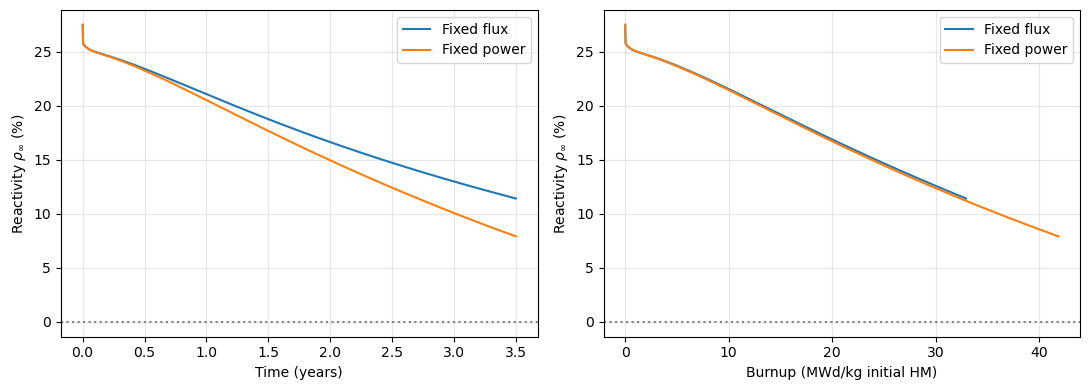

,final_burnup,final_flux,final_power,final_rho
case,,,,
Fixed flux,32.924020,1.499582e+14,192.848359,0.114107
Fixed power,41.836879,2.559859e+14,300.000000,0.079074


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for label, r in histories.items():
    for ax, axis in zip(axes, ("time", "burnup")):
        x, xlabel = r.axis(axis, time_unit="years")
        ax.plot(x, 100*r.neutronics(CLOSURE)["rho"], label=label)
        ax.set(xlabel=xlabel, ylabel=r"Reactivity $\rho_\infty$ (%)")
for ax in axes:
    ax.axhline(0, color="gray", linestyle=":")
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
plt.show()

display(pd.DataFrame([
    dict(case=label, final_burnup=r.burnup_mwd_kg[-1],
         final_flux=np.broadcast_to(r.total_flux, r.time_s.shape)[-1],
         final_power=r.power_density_w_cm3[-1],
         final_rho=r.neutronics(CLOSURE)["rho"][-1])
    for label, r in histories.items()
]).set_index("case"))

The cases start at the same power and flux. At fixed power the flux generally rises to compensate for the evolving fission inventory, and burnup increases linearly with time. Compare the curves at the same burnup as well as at the same time.

Fixed power is a more useful irradiation assumption for this lesson, but the model still prescribes the spectrum, retains approximate microscopic data, and omits thermal feedback and control schedules. The reactivity curve measures available excess reactivity; imposed power does not guarantee critical operation.

### Power, mass, and burnup: a reactor-scale check

Suppose a 3000 MWth reactor contains $10^7$ cm³ of fuel. What power density and initial heavy-metal mass does that imply? What is its burnup after one day and five full-power years? Use the same fuel density and enrichment as the depletion calculation.

In [5]:
REACTOR_POWER_MW = 3000.0
FUEL_VOLUME_CM3 = 1e7
hm_kg = fixed_power.initial_hm_kg_cm3 * FUEL_VOLUME_CM3
print(f"Fuel power density: {REACTOR_POWER_MW*1e6/FUEL_VOLUME_CM3:.1f} W/cm^3")
print(f"Initial heavy-metal mass: {hm_kg/1000:.2f} tonnes")
print(f"One-day burnup: {REACTOR_POWER_MW/hm_kg:.4f} MWd/kg")
print(f"Five-year burnup: {REACTOR_POWER_MW*(5*YEAR/DAY)/hm_kg:.2f} MWd/kg")

Fuel power density: 300.0 W/cm^3
Initial heavy-metal mass: 91.67 tonnes
One-day burnup: 0.0327 MWd/kg
Five-year burnup: 59.77 MWd/kg


## 3. Fit the fixed-power curve for the LRM

Approximate the fuel reactivity over a chosen burnup interval by

$$\boxed{\rho_\infty(B)=\rho_0-AB}.$$

Fit dimensionless reactivity on an evenly spaced burnup grid so the dense startup time samples do not dominate the least-squares objective. For this 4% enriched fuel, fit from **1 to 40 MWd/kg initial HM**. Starting at 1 MWd/kg (about 31 full-power days here) bypasses the initial xenon drop; 40 MWd/kg sets the upper end of the intended fuel-use range. Both the interval and its residuals matter: a straight line cannot capture all depletion curvature. The fitted $\rho_0$ is an extrapolated intercept, not necessarily the actual fresh-fuel reactivity.

Fit interval: 1–40 MWd/kg initial HM
rho_0 = 0.256699; A = 0.004394 per (MWd/kg)
RMS residual: 177.6 pcm
Maximum absolute residual: 458.0 pcm


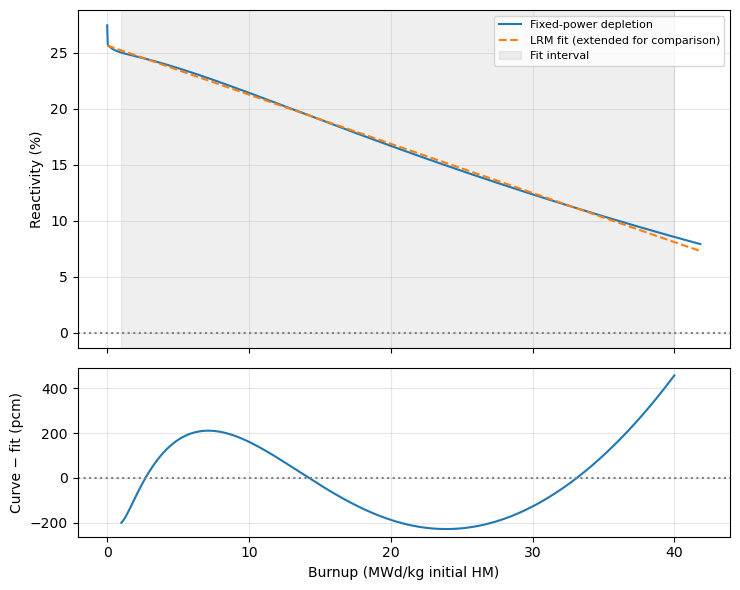

In [6]:
FIT_BURNUP = (1.0, 40.0)  # MWd/kg initial HM; adjust to study sensitivity
burnup = fixed_power.burnup_mwd_kg
rho_power = fixed_power.neutronics(CLOSURE)["rho"]
lo, hi = FIT_BURNUP
if not burnup[0] <= lo < hi <= burnup[-1]:
    raise ValueError("The fit interval must be covered by the fixed-power history.")
B_fit = np.linspace(lo, hi, 301)
rho_fit_data = np.interp(B_fit, burnup, rho_power)
slope, rho_0 = np.polyfit(B_fit, rho_fit_data, 1)
A = -slope
if A <= 0:
    raise ValueError("This LRM requires reactivity to decrease over the fit interval.")

def rho_lrm(B):
    return rho_0 - A*np.asarray(B)

residual_pcm = 1e5*(rho_fit_data - rho_lrm(B_fit))
print(f"Fit interval: {lo:g}–{hi:g} MWd/kg initial HM")
print(f"rho_0 = {rho_0:.6f}; A = {A:.6f} per (MWd/kg)")
print(f"RMS residual: {np.sqrt(np.mean(residual_pcm**2)):.1f} pcm")
print(f"Maximum absolute residual: {np.max(np.abs(residual_pcm)):.1f} pcm")

fig, axes = plt.subplots(2, 1, figsize=(7.5, 6), sharex=True,
                         gridspec_kw={"height_ratios": [2, 1]})
axes[0].plot(burnup, 100*rho_power, label="Fixed-power depletion")
axes[0].plot(burnup, 100*rho_lrm(burnup), "--", label="LRM fit (extended for comparison)")
axes[0].axvspan(lo, hi, alpha=0.12, color="gray", label="Fit interval")
axes[0].axhline(0, color="gray", linestyle=":")
axes[0].set(ylabel="Reactivity (%)")
axes[0].legend(fontsize=8)
axes[1].plot(B_fit, residual_pcm)
axes[1].axhline(0, color="gray", linestyle=":")
axes[1].set(xlabel="Burnup (MWd/kg initial HM)", ylabel="Curve − fit (pcm)")
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

### Extrapolation is not a fuel-use prediction

The intended range for this 4% fuel ends at about 40 MWd/kg. The calculation extends only slightly beyond that to cover the fit interval. If the curve remains positive throughout this range, there is no simulated zero-reactivity burnup to report. The LRM zero below is a mathematical extrapolation, not a proposed discharge burnup.

In [7]:
crossings = np.flatnonzero((rho_power[:-1] >= 0) & (rho_power[1:] < 0))
if len(crossings):
    j = crossings[0]
    B_zero = burnup[j] - rho_power[j]*(burnup[j+1]-burnup[j])/(rho_power[j+1]-rho_power[j])
    print(f"Fixed-power curve reaches rho = 0 at {B_zero:.2f} MWd/kg.")
else:
    print("No downward zero crossing in the simulated history.")
print(f"Extrapolated LRM zero-reactivity burnup: {rho_0/A:.2f} MWd/kg.")

No downward zero crossing in the simulated history.
Extrapolated LRM zero-reactivity burnup: 58.41 MWd/kg.


## 4. The three LRM assumptions

1. The equilibrium core has $N$ equal-mass batches of initially identical fuel. Each batch gains the same burnup $B_c$ per cycle.
2. Fuel reactivity is linear in burnup, $\rho_\infty(B)=\rho_0-AB$, using the coefficients fitted above.
3. Core reactivity is the weighted sum of batch reactivities minus a leakage penalty:

$$\boxed{\rho_{\rm core}=\sum_{i=1}^N w_i\rho_i-\rho_L},\qquad
\sum_iw_i=1.$$

The simplest LRM uses $w_i=1/N$. This averaging is an approximation to core neutronics. Here $\rho_L$ is an additive reactivity penalty; it is distinct from a multiplicative nonleakage probability.

### Batch nomenclature

For three batches, refueling replaces one third of the core. At beginning of cycle (BOC), the batch burnups are $0$, $B_c$, and $2B_c$. At end of cycle (EOC), they are $B_c$, $2B_c$, and $3B_c$; the oldest fuel is discharged.

The **cycle burnup** is $B_c$. The **discharge burnup** is $B_d=NB_c$. In this idealized model, the limiting EOC occurs when available excess core reactivity is zero. Positive BOC excess would need to be controlled in operation.

### Example: a proposed two-batch cycle

Using our fitted coefficients, take $N=2$, $\rho_L=0.05$, and propose $B_c=10$ MWd/kg. Compute the BOC and EOC batch and core reactivities. Does the proposed EOC exhaust the available excess reactivity?

In [8]:
RHO_L = 0.05                       # illustrative additive leakage penalty
N_BATCHES = 2
PROPOSED_BC = 10.0
batch_boc = np.arange(N_BATCHES)*PROPOSED_BC
batch_eoc = np.arange(1, N_BATCHES+1)*PROPOSED_BC
for name, b in (("BOC", batch_boc), ("EOC", batch_eoc)):
    batch_rho = rho_lrm(b)
    core_rho = batch_rho.mean() - RHO_L
    print(f"{name}: batch burnups = {b}, batch rho = {batch_rho}")
    print(f"     core rho = {core_rho:.5f} ({100*core_rho:.2f}%)")

BOC: batch burnups = [ 0. 10.], batch rho = [0.25669882 0.2127542 ]
     core rho = 0.18473 (18.47%)
EOC: batch burnups = [10. 20.], batch rho = [0.2127542  0.16880958]
     core rho = 0.14078 (14.08%)


## 5. Determine cycle and discharge burnup

At EOC the batch burnups are $B_c,2B_c,\ldots,NB_c$, so

$$0=\frac1N\sum_{i=1}^N(\rho_0-AiB_c)-\rho_L
=\rho_0-\rho_L-A\frac{N+1}{2}B_c.$$

Using $\sum_{i=1}^Ni=N(N+1)/2$ gives

$$\boxed{B_c=\frac{2(\rho_0-\rho_L)}{A(N+1)}},\qquad
\boxed{B_d=\frac{2N(\rho_0-\rho_L)}{A(N+1)}}.$$

Compare one-, two-, and three-batch cores. More batches shorten each cycle while increasing discharge burnup. These formulas require $A>0$ and $\rho_0>\rho_L$.

In [9]:
if rho_0 <= RHO_L:
    raise ValueError("The fit has insufficient initial reactivity for this leakage penalty.")
rows = []
for n in (1, 2, 3):
    bc = 2*(rho_0-RHO_L)/(A*(n+1))
    bd = n*bc
    eoc_burnups = np.arange(1, n+1)*bc
    eoc_lrm = rho_lrm(eoc_burnups).mean() - RHO_L
    np.testing.assert_allclose(eoc_lrm, 0., atol=1e-12)
    covered = eoc_burnups[-1] <= burnup[-1]
    curve_eoc = (np.interp(eoc_burnups, burnup, rho_power).mean() - RHO_L
                 if covered else np.nan)
    rows.append(dict(batches=n, cycle_MWd_kg=bc, discharge_MWd_kg=bd,
                     cycle_full_power_days=bc*8.64e10*fixed_power.initial_hm_kg_cm3/POWER_DENSITY/DAY,
                     LRM_EOC_rho=eoc_lrm, depletion_curve_EOC_rho=curve_eoc,
                     all_EOC_batches_in_fit=bool(np.all((eoc_burnups >= lo) & (eoc_burnups <= hi)))))
cycle_table = pd.DataFrame(rows).set_index("batches")
display(cycle_table)

,cycle_MWd_kg,discharge_MWd_kg,cycle_full_power_days,LRM_EOC_rho,depletion_curve_EOC_rho,all_EOC_batches_in_fit
batches,,,,,,
1,47.036208,47.036208,1437.246616,1.387779e-17,NaN,False
2,31.357472,62.714944,958.164410,-1.387779e-17,NaN,False
3,23.518104,70.554312,718.623308,1.387779e-17,NaN,False


The `depletion_curve_EOC_rho` column substitutes the nonlinear fixed-power curve into the same equal-weight batch average at the LRM-predicted EOC. Its difference from zero shows the effect of the linear fit under that averaging assumption. This remains a comparison of model assumptions, not a full-core calculation.

Check `all_EOC_batches_in_fit` before using a predicted cycle: a batch outside the fit interval uses an extrapolation. Changing the fit interval changes $\rho_0$, $A$, and the predicted cycle lengths. Large residuals are a reason to reconsider the linear approximation.

With this fit, the idealized cycle formulas can predict discharge burnups above 40 MWd/kg. Those values extrapolate beyond the intended range for this fuel; they illustrate the LRM algebra rather than establish acceptable fuel residence. The nonlinear comparison is left blank when the required batch burnups exceed the simulated history.

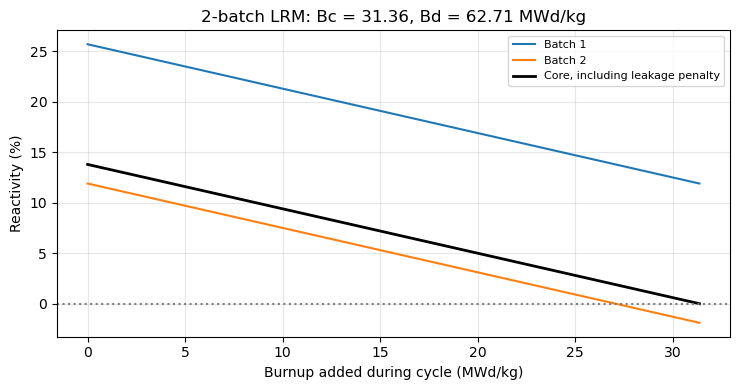

In [10]:
n = N_BATCHES
bc = float(cycle_table.loc[n, "cycle_MWd_kg"])
cycle_progress = np.linspace(0, bc, 201)
fig, ax = plt.subplots(figsize=(7.5, 4))
for i in range(n):
    ax.plot(cycle_progress, 100*rho_lrm(i*bc + cycle_progress),
            label=f"Batch {i+1}")
core_rho = np.mean([rho_lrm(i*bc + cycle_progress) for i in range(n)], axis=0) - RHO_L
ax.plot(cycle_progress, 100*core_rho, color="black", linewidth=2, label="Core, including leakage penalty")
ax.axhline(0, color="gray", linestyle=":")
ax.set(xlabel="Burnup added during cycle (MWd/kg)", ylabel="Reactivity (%)",
       title=f"{n}-batch LRM: Bc = {bc:.2f}, Bd = {n*bc:.2f} MWd/kg")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Explore

- Change `FIT_BURNUP`. How stable are the cycle and discharge predictions?
- Change enrichment or power density and rerun the notebook. Which changes affect the curve versus burnup, and which mainly change the time scale?
- Compare the nonlinear batch-average EOC reactivity with the fitted LRM value. Is the linear approximation adequate for the intended calculation?

The depletion module isolates inventory and normalization effects. The LRM adds a separate approximation for batch averaging and leakage; neither supplies a self-consistent transport spectrum or core power distribution.